# Saisuipoin Outlier Detection and Cleaning

**Objective**: Verify the integrity of the `saisuipoin` (Layer Category) column and filter out inconsistencies. 

**Context**:
- `saisuipoin = 1`: Defined as **Upper Layer/Surface**.
- `saisuipoin = 2`: Defined as **Lower Layer/Bottom**.

Preliminary analysis suggests that `saisuipoin=1` contains samples at significant depths (e.g., > 100m), which contradicts the "Upper Layer" definition. This notebook visualizes these anomalies and creates a cleaned dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys
from pathlib import Path

# Add project root to path for imports
project_root = Path("..").resolve()
sys.path.append(str(project_root))

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 6]

## 1. Load Data

In [2]:
# Apply numeric conversion to saisuidept immediately
file_path = project_root / 'data' / 'processed' / 'merged_gdf.feather'

df = pd.read_feather(file_path)

# Ensure saisuidept is numeric (coercing errors to NaN)
df['saisuidept_num'] = pd.to_numeric(df['saisuidept'], errors='coerce')
df['depth_num'] = pd.to_numeric(df['depth'], errors='coerce')

print(f"Data Shape: {df.shape}")
print(df[['uniqueid', 'year', 'saisuipoin', 'saisuidept_num', 'depth_num']].head())

Data Shape: (41346, 67)
     uniqueid  year  saisuipoin  saisuidept_num  depth_num
0  0000001729  1981           1             0.5        8.0
1  0000001730  1981           1             0.5        7.0
2  0000001732  1981           1             0.5        7.0
3  0000001733  1981           2             6.0        8.0
4  0000001734  1981           2             6.0        7.0


## 2. Visualize Current Structure

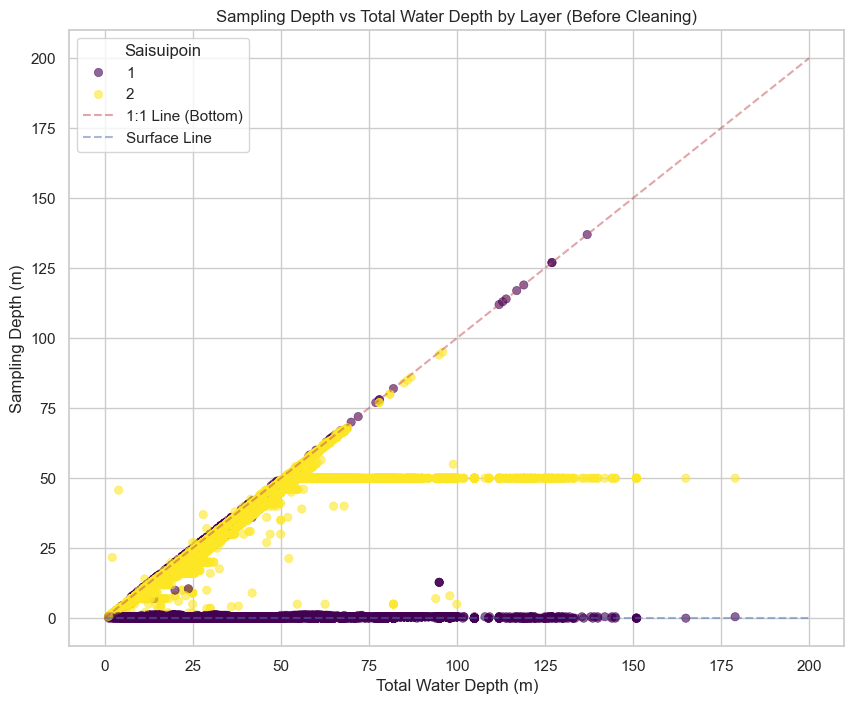

In [3]:
# Plot Sampling Depth (y) vs Total Water Depth (x), colored by Saisuipoin
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df, x='depth_num', y='saisuidept_num', hue='saisuipoin', 
                palette='viridis', alpha=0.6, edgecolor=None)

plt.title('Sampling Depth vs Total Water Depth by Layer (Before Cleaning)')
plt.xlabel('Total Water Depth (m)')
plt.ylabel('Sampling Depth (m)')
plt.plot([0, 200], [0, 200], 'r--', alpha=0.5, label='1:1 Line (Bottom)')
plt.plot([0, 200], [0, 0], 'b--', alpha=0.5, label='Surface Line')
plt.legend(title='Saisuipoin')
plt.show()

**Observation**:
*   **Layer 1 (Purple)** should ideally form a flat line near y=0 (Surface).
*   **Layer 2 (Yellow)** should follow the 1:1 red line (Bottom).
*   Points colored as Layer 1 but lying on the 1:1 line (or deep) are outliers.

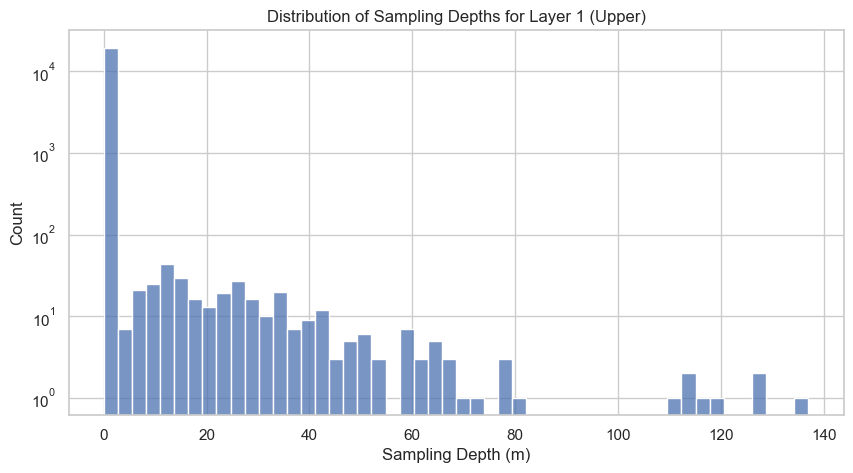

Layer 1 Depth Statistics:
count    19833.000000
mean         0.773292
std          4.501024
min          0.000000
25%          0.000000
50%          0.500000
75%          0.500000
max        137.000000
Name: saisuidept_num, dtype: float64


In [4]:
# Investigate the distribution of Layer 1 depths
layer1 = df[df['saisuipoin'] == 1]

plt.figure(figsize=(10, 5))
sns.histplot(layer1['saisuidept_num'], bins=50, kde=False)
plt.title('Distribution of Sampling Depths for Layer 1 (Upper)')
plt.xlabel('Sampling Depth (m)')
plt.yscale('log')  # Log scale to see outliers
plt.show()

print("Layer 1 Depth Statistics:")
print(layer1['saisuidept_num'].describe())

## 3. Define and Apply Filter

We will define a "Surface" threshold for Layer 1. Based on typical monitoring, the upper layer is usually 0.5m or 2m. We will be conservative and flag any Layer 1 sample deeper than **10m** as an outlier, or samples where `saisuidept` is suspiciously close to `depth` while being labeled as 1.

In [5]:
SURFACE_THRESHOLD_M = 10.0

# Criteria: Saisuipoin is 1 AND Saisuidept > Threshold
outliers = df[(df['saisuipoin'] == 1) & (df['saisuidept_num'] > SURFACE_THRESHOLD_M)]

print(f"Identified {len(outliers)} outliers in Layer 1 (Depth > {SURFACE_THRESHOLD_M}m).")
display(outliers[['uniqueid', 'year', 'saisuipoin', 'saisuidept_num', 'depth_num', 'locationna']].head())

Identified 276 outliers in Layer 1 (Depth > 10.0m).


,uniqueid,year,saisuipoin,saisuidept_num,depth_num,locationna
3899,0000006912,1984,1,11.5,13.5,福岡県632
9715,0000015793,1990,1,12.0,NaN,福岡県714
9750,0000015801,1990,1,10.5,NaN,福岡県715
10308,0000017274,1991,1,16.0,18.0,福岡県714
10310,0000017276,1991,1,14.0,16.0,福岡県714


In [6]:
# Create Cleaned Dataset
clean_df = df[~((df['saisuipoin'] == 1) & (df['saisuidept_num'] > SURFACE_THRESHOLD_M))].copy()

print(f"Original Shape: {df.shape}")
print(f"Cleaned Shape:  {clean_df.shape}")
print(f"Removed {len(df) - len(clean_df)} records.")

Original Shape: (41346, 67)
Cleaned Shape:  (41070, 67)
Removed 276 records.


## 4. Verify Cleaning

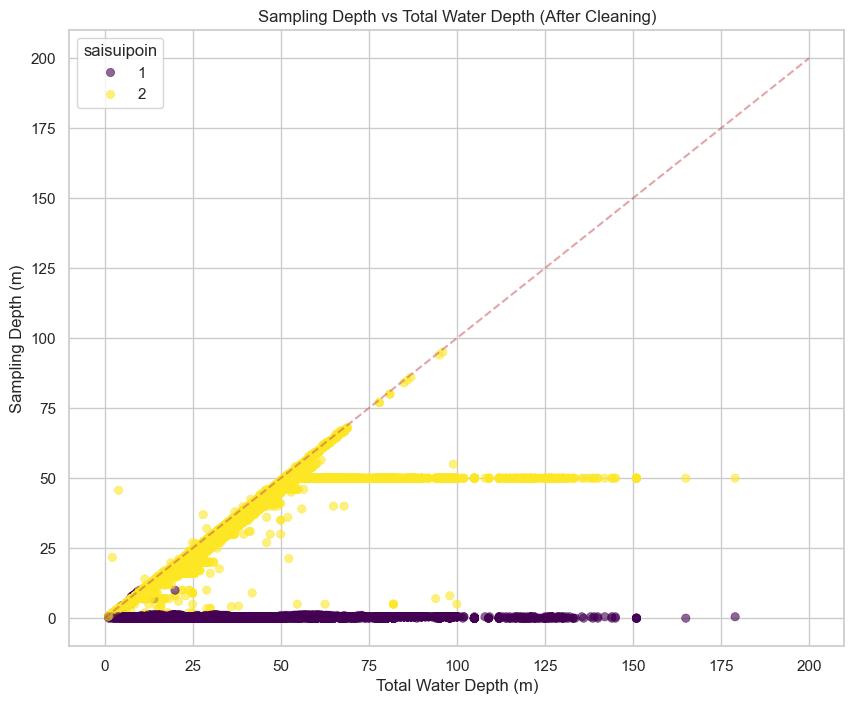

In [7]:
# Plot again to confirm structure
plt.figure(figsize=(10, 8))
sns.scatterplot(data=clean_df, x='depth_num', y='saisuidept_num', hue='saisuipoin', 
                palette='viridis', alpha=0.6, edgecolor=None)

plt.title('Sampling Depth vs Total Water Depth (After Cleaning)')
plt.xlabel('Total Water Depth (m)')
plt.ylabel('Sampling Depth (m)')
plt.plot([0, 200], [0, 200], 'r--', alpha=0.5)
plt.show()

## 5. Save Cleaned Dataset

In [8]:
output_path = project_root / 'data' / 'processed' / 'merged_gdf_saisuipoin_cleaned.feather'
clean_df.to_feather(output_path)

print(f"Saved cleaned dataset to: {output_path}")

Saved cleaned dataset to: C:\Users\reyha\Documents\SIS_Analysis\data\processed\merged_gdf_saisuipoin_cleaned.feather


In [10]:
# === Find out the depth range of both 'saisuipoin' category ===

# Convert 'depth' column to numeric, forcing non-numeric values to NaN (since it is currently Object type)
clean_df['saisuidept_num'] = pd.to_numeric(clean_df['saisuidept'], errors='coerce')

# Group by 'saisuipoin' and calculate the minimum and maximum depth
depth_ranges = clean_df.groupby('saisuipoin')['saisuidept_num'].agg(['min', 'max'])

# Display the results
print("Depth ranges for each 'saisuipoin' category:")
print(depth_ranges)

Depth ranges for each 'saisuipoin' category:
            min   max
saisuipoin           
1           0.0  10.0
2           0.2  95.0


This is the correct depth range (saisuidept) of both saisuipoin category.